# 01 — Profiling the raw DataCo data

**Goal:** understand the raw order-item data *before* changing anything.
Every cleaning rule in [`cleaning_rules.md`](cleaning_rules.md) points back to evidence in this notebook.

Read-only: nothing here modifies the data. The rules themselves live in `clean_pipeline.py` and are demonstrated in `02_cleaning_decisions.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "Clean" else Path.cwd()
RAW = ROOT / "Data" / "Raw" / "DataCoSupplyChainDataset.csv"

df = pd.read_csv(RAW, encoding="latin-1")
df.columns = df.columns.str.strip()  # some raw headers have trailing spaces
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")

180,519 rows x 53 columns


## 1. Shape and grain
What does one row represent?

In [2]:
summary = pd.Series({
    "rows": len(df),
    "fully duplicated rows": df.duplicated().sum(),
    "order_item_id unique?": df["Order Item Id"].is_unique,
    "orders": df["Order Id"].nunique(),
    "customers": df["Customer Id"].nunique(),
    "products": df["Product Card Id"].nunique(),
    "categories": df["Category Id"].nunique(),
    "departments": df["Department Id"].nunique(),
    "markets": df["Market"].nunique(),
    "destination countries": df["Order Country"].nunique(),
})
summary.to_frame("value")

,value
rows,180519
fully duplicated rows,0
order_item_id unique?,True
orders,65752
customers,20652
products,118
categories,51
departments,11
markets,5
destination countries,164


**Finding:** `Order Item Id` is unique and there are no duplicate rows → the grain is **one row per order item** and **no rows need removing**.

## 2. Missing values

In [3]:
nulls = df.isna().agg(["sum", "mean"]).T.rename(columns={"sum": "null rows", "mean": "% null"})
nulls["null rows"] = nulls["null rows"].astype(int)
nulls["% null"] = (nulls["% null"] * 100).round(3)
nulls[nulls["null rows"] > 0].sort_values("null rows", ascending=False)

,null rows,% null
Product Description,180519,100.000
Order Zipcode,155679,86.240
Customer Lname,8,0.004
Customer Zipcode,3,0.002


**Finding:** `Product Description` is 100% empty and `Order Zipcode` is 86% empty (→ **R02**). `Customer Lname` (8 rows) is dropped anyway as personal data; the 3 missing `Customer Zipcode` values are the shifted rows in §8.

## 3. Columns with only one value

In [4]:
constant = {c: df[c].unique()[0] for c in df.columns if df[c].nunique(dropna=False) == 1}
pd.Series(constant, name="only value").to_frame()

,only value
Customer Email,XXXXXXXXX
Customer Password,XXXXXXXXX
Product Description,NaN
Product Status,0


**Finding:** email and password are already masked as `XXXXXXXXX` in every row, so they carry no information. `Product Status` is always 0 (→ **R01**, **R02**).

## 4. Duplicate columns
Several columns look like copies of each other. Check row by row.

In [5]:
pairs = [
    ("Benefit per order", "Order Profit Per Order"),
    ("Sales per customer", "Order Item Total"),
    ("Order Customer Id", "Customer Id"),
    ("Product Category Id", "Category Id"),
    ("Order Item Product Price", "Product Price"),
    ("Order Item Cardprod Id", "Product Card Id"),
]
pd.DataFrame(
    [(a, b, f"{(df[a] == df[b]).mean():.0%}") for a, b in pairs],
    columns=["column", "compared with", "rows identical"],
)

,column,compared with,rows identical
0,Benefit per order,Order Profit Per Order,100%
1,Sales per customer,Order Item Total,100%
2,Order Customer Id,Customer Id,100%
3,Product Category Id,Category Id,100%
4,Order Item Product Price,Product Price,100%
5,Order Item Cardprod Id,Product Card Id,100%


**Finding:** all six pairs are 100% identical → drop one of each (**R03**).

## 5. Categorical columns

In [6]:
for col in ["Market", "Shipping Mode", "Delivery Status", "Order Status", "Type", "Customer Segment"]:
    print(df[col].value_counts().to_string(), end="\n\n")

Market
LATAM           51594
Europe          50252
Pacific Asia    41260
USCA            25799
Africa          11614

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893

Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616

Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226



### Order status vs delivery status

In [7]:
pd.crosstab(df['Order Status'], df['Delivery Status'])

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Order Status,,,,
CANCELED,0,0,3692,0
CLOSED,4809,11109,0,3698
COMPLETE,14136,34199,0,11156
ON_HOLD,2413,5450,0,1941
PAYMENT_REVIEW,420,1082,0,391
PENDING,4857,11712,0,3658
PENDING_PAYMENT,9588,22922,0,7322
PROCESSING,5369,12503,0,4030
SUSPECTED_FRAUD,0,0,4062,0


**Finding:** every `CANCELED` and `SUSPECTED_FRAUD` order has delivery status `Shipping canceled`, and only those do. They're real business events, so we **keep and flag** them (→ **R13**, **R14**).

### Is `Late_delivery_risk` a risk score?

In [8]:
pd.crosstab(df['Late_delivery_risk'], df['Delivery Status'])

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Late_delivery_risk,,,,
0,41592,0,7754,32196
1,0,98977,0,0


**Finding:** it is exactly 1 when the item **was** late. It's an outcome, not a risk, so it's renamed `is_late` (→ **R04**).

### Signs of synthetic data

In [9]:
pd.crosstab(df['Order Status'], df['Type'])

Type,CASH,DEBIT,PAYMENT,TRANSFER
Order Status,,,,
CANCELED,0,0,0,3692
CLOSED,19616,0,0,0
COMPLETE,0,59491,0,0
ON_HOLD,0,9804,0,0
PAYMENT_REVIEW,0,0,1893,0
PENDING,0,0,0,20227
PENDING_PAYMENT,0,0,39832,0
PROCESSING,0,0,0,21902
SUSPECTED_FRAUD,0,0,0,4062


In [10]:
pd.crosstab(df['Shipping Mode'], df['Days for shipment (scheduled)'])

Days for shipment (scheduled),0,1,2,4
Shipping Mode,,,,
First Class,0,27814,0,0
Same Day,9737,0,0,0
Second Class,0,0,35216,0
Standard Class,0,0,0,107752


**Findings:**
- Payment type is **fully determined** by order status (every `CLOSED` order is `CASH`, every `COMPLETE` is `DEBIT`…). This is unrealistic, a sign the dataset is partly synthetic. It's mentioned in the report, not "fixed".
- The scheduled days are a **fixed rule per shipping mode**: Same Day = 0, First = 1, Second = 2, Standard = 4. This is the SLA we test in Question 02.

## 6. Numbers

In [11]:
num_cols = ["Order Item Quantity", "Product Price", "Sales", "Order Item Discount",
            "Order Item Discount Rate", "Order Item Total", "Order Profit Per Order",
            "Order Item Profit Ratio", "Days for shipping (real)", "Days for shipment (scheduled)"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Order Item Quantity,180519.0,2.13,1.45,1.00,1.00,1.00,3.00,5.00
Product Price,180519.0,141.23,139.73,9.99,50.00,59.99,199.99,1999.99
Sales,180519.0,203.77,132.27,9.99,119.98,199.92,299.95,1999.99
Order Item Discount,180519.0,20.66,21.80,0.00,5.40,14.00,29.99,500.00
Order Item Discount Rate,180519.0,0.10,0.07,0.00,0.04,0.10,0.16,0.25
Order Item Total,180519.0,183.11,120.04,7.49,104.38,163.99,247.40,1939.99
Order Profit Per Order,180519.0,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80
Order Item Profit Ratio,180519.0,0.12,0.47,-2.75,0.08,0.27,0.36,0.50
Days for shipping (real),180519.0,3.50,1.62,0.00,2.00,3.00,5.00,6.00
Days for shipment (scheduled),180519.0,2.93,1.37,0.00,2.00,4.00,4.00,4.00


### Does the money add up?

In [12]:
gross_ok = np.isclose(df["Sales"], df["Product Price"] * df["Order Item Quantity"])
net_gap = df["Sales"] - df["Order Item Discount"] - df["Order Item Total"]
rate_gap = df["Order Item Discount"] - df["Sales"] * df["Order Item Discount Rate"]

pd.Series({
    "sales = price x quantity": f"{gross_ok.mean():.1%}",
    "net = sales - discount (within $0.001)": f"{(net_gap.abs() <= 0.001).mean():.1%}",
    "rows off by ~$0.01": (net_gap.abs() > 0.001).sum(),
    "largest gap ($)": round(net_gap.abs().max(), 4),
    "discount != sales x rate (> $0.01)": (rate_gap.abs() > 0.01).sum(),
}).to_frame("result")

,result
sales = price x quantity,100.0%
net = sales - discount (within $0.001),97.4%
rows off by ~$0.01,4613
largest gap ($),0.01
discount != sales x rate (> $0.01),10029


**Findings:**
- `Sales` is **gross** (price × quantity) and `Order Item Total` is **net** (after discount). They're renamed `sales` / `net_sales` (→ **R04**).
- 4,613 rows are off by exactly 1 cent, a float-storage artefact → round money to 2 dp (→ **R07**).
- `discount_rate` doesn't always match the discount amount (~$1 off in about 10k rows). The **amount** reconciles to net sales, so it's the source of truth; the rate is kept as given.

### Loss-making items

In [13]:
loss = df["Order Profit Per Order"] < 0
print(f"{loss.mean():.1%} of items have negative profit; worst profit ratio = {df['Order Item Profit Ratio'].min()}")

18.7% of items have negative profit; worst profit ratio = -2.75


**Finding:** losses are frequent but plausible. This is the profit-leakage story (Question 03), so it's **kept**.

## 7. Dates

In [14]:
order_date = pd.to_datetime(df["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
ship_date = pd.to_datetime(df["shipping date (DateOrders)"], format="%m/%d/%Y %H:%M")
day_gap = (ship_date.dt.normalize() - order_date.dt.normalize()).dt.days

pd.Series({
    "parse failures": order_date.isna().sum() + ship_date.isna().sum(),
    "first order": order_date.min(),
    "last order": order_date.max(),
    "ship date before order date": (ship_date < order_date).sum(),
    "real days = ship - order days": f"{(day_gap == df['Days for shipping (real)']).mean():.0%}",
}).to_frame("result")

,result
parse failures,0
first order,2015-01-01 00:00:00
last order,2018-01-31 23:38:00
ship date before order date,0
real days = ship - order days,100%


**Finding:** both dates parse cleanly with one format and are internally consistent → parse to datetime (→ **R05**).

### Volume over time

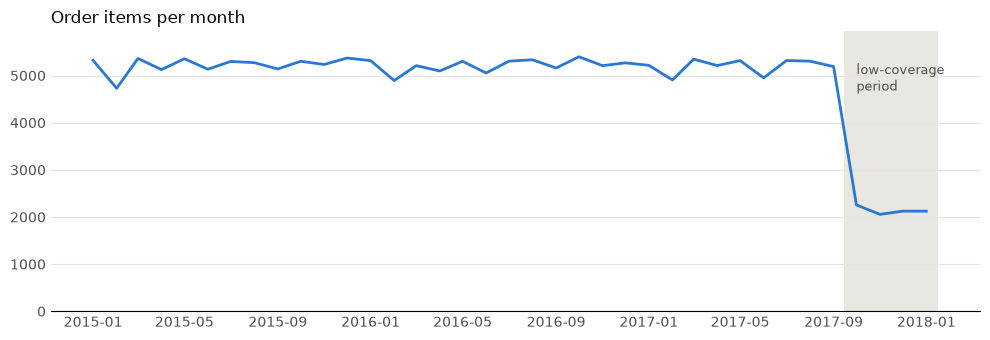

In [15]:
monthly = order_date.dt.to_period("M").value_counts().sort_index()
low = monthly.index >= pd.Period("2017-10", "M")

fig, ax = plt.subplots(figsize=(10, 3.5))
x = monthly.index.to_timestamp()
ax.plot(x, monthly.values, color="#2a78d6", linewidth=2)
ax.axvspan(pd.Timestamp("2017-09-15"), x[-1] + pd.Timedelta(days=15), color="#d3d1c7", alpha=0.5, linewidth=0)
ax.text(pd.Timestamp("2017-10-01"), monthly.max() * 0.98, "low-coverage\nperiod", va="top", fontsize=9, color="#52514e")
ax.set_title("Order items per month", loc="left", fontsize=12)
ax.set_ylim(0, monthly.max() * 1.1)
ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors="#52514e", length=0)
plt.tight_layout()
plt.show()

In [16]:
period = np.where(order_date >= "2017-10-01", "Oct 2017 - Jan 2018", "Jan 2015 - Sep 2017")
g = df.assign(period=period, month=order_date.dt.to_period("M")).groupby("period")
pd.DataFrame({
    "items per month": g.size() / g["month"].nunique(),
    "markets": g["Market"].nunique(),
    "products": g["Product Card Id"].nunique(),
    "items per order": g.size() / g["Order Id"].nunique(),
}).round(1).T

period,Jan 2015 - Sep 2017,Oct 2017 - Jan 2018
items per month,5211.0,2139.2
markets,5.0,2.0
products,100.0,31.0
items per order,3.0,1.0


**Finding (the most important one):** from October 2017 the data changes shape: ~60% fewer items, only **2 of 5 markets**, 31 products, and 1 item per order instead of 3. This looks like a change in data collection, not a demand collapse.
→ keep the rows, flag `is_low_coverage_period` (**R16**), and use Jan 2015 – Sep 2017 for trends.

## 8. Geography: two different locations

In [17]:
print("Customer Country (store):", df["Customer Country"].value_counts().to_dict())
print("Order Country (destination): ", df["Order Country"].nunique(), "countries")
df["Order Country"].value_counts().head(10).to_frame("items")

Customer Country (store): {'EE. UU.': 111146, 'Puerto Rico': 69373}
Order Country (destination):  164 countries


,items
Order Country,
Estados Unidos,24840
Francia,13222
México,13172
Alemania,9564
Australia,8497
Brasil,7987
Reino Unido,7302
China,5758
Italia,4989


**Findings:**
- `Customer *` columns and `Latitude/Longitude` are the **store** (only US and Puerto Rico). `Order *` columns are the **delivery destination** (global). Renamed so nobody mixes them up: `store_latitude`, `order_country`… (→ **R04**).
- Country names are in **Spanish** (`Estados Unidos`, `Francia`, `EE. UU.`) → translate (→ **R09**).

### Shifted address rows

In [18]:
df[df["Customer State"].str.isdigit()][["Customer Street", "Customer City", "Customer State", "Customer Zipcode"]]

,Customer Street,Customer City,Customer State,Customer Zipcode
35704,Elk Grove,CA,95758,NaN
46440,Elk Grove,CA,95758,NaN
82511,El Monte,CA,91732,NaN


**Finding:** in 3 rows the values slid one column to the right (city = `CA`, state = a zip code) → shift back (→ **R10**).

### Store longitude sign

In [19]:
pos = df[df["Longitude"] > 0]
print(f"{len(pos)} rows of US/PR stores with positive longitude (would plot in Asia)")
pos[["Customer City", "Customer State", "Latitude", "Longitude"]].drop_duplicates().head()

105 rows of US/PR stores with positive longitude (would plot in Asia)


,Customer City,Customer State,Latitude,Longitude
2034,Douglasville,GA,33.728558,84.742676
4138,Las Vegas,NV,36.163929,115.049789
8864,Tampa,FL,28.007509,82.461998
18673,Washington,DC,38.911991,77.092094
42977,Las Vegas,NV,36.198677,115.263077


**Finding:** US longitudes must be negative → negate (→ **R11**).

### Zip codes lost their leading zeros

In [20]:
zip_len = df["Customer Zipcode"].dropna().astype(int).astype(str).str.len()
pd.crosstab(df.loc[zip_len.index, "Customer Country"], zip_len.rename("zip digits"))

zip digits,3,4,5
Customer Country,,,
EE. UU.,0,6135,105008
Puerto Rico,69373,0,0


**Finding:** zips were stored as numbers, so leading zeros were lost: all Puerto Rico zips are 3 digits (`725` should be `00725`) and 6,135 US zips are 4 digits (north-east states, e.g. `2138` should be `02138`). Zips are codes, not numbers → 5-char text (→ **R06**).

## 9. Text quality

In [21]:
text_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
ws = {c: df[c].str.contains(r"^\s|\s$|\s{2}", regex=True, na=False).sum() for c in text_cols}
pd.Series(ws)[lambda s: s > 0].sort_values(ascending=False).to_frame("cells with extra spaces")

,cells with extra spaces
Order Region,17925
Customer Street,3036
Product Name,1774
Category Name,1543
Product Image,886
Department Name,362


In [22]:
print(sorted(v for v in df["Category Name"].unique() if v != v.strip() or "  " in v))

['As Seen on  TV!', 'Baby ', 'Books ', 'CDs ', 'Cameras ']


**Finding:** about 21k cells have trailing or double spaces → trim and collapse (→ **R08**).

### Same category name, two categories

In [23]:
names = df.groupby("Category Name")["Category Id"].nunique()
dup = names[names > 1].index
df[df["Category Name"].isin(dup)].groupby(["Category Name", "Category Id", "Department Name"]).size().to_frame("items")

items
Category Name Category Id Department Name       
Electronics   13          Footwear          1127
              37          Outdoors          2029

**Finding:** `Electronics` is two different categories in two departments → add the department to the name (→ **R12**).

## Summary: findings → rules

| Finding | Rule |
|---|---|
| Masked / personal columns (email, password, names, street) | R01 drop |
| Empty, constant or URL columns | R02 drop |
| 6 columns 100% identical to others | R03 drop |
| Messy and misleading names (`Order Profit Per Order` is item-level) | R04 rename |
| Dates stored as text | R05 parse |
| 75,508 zips missing leading zeros (PR + north-east US) | R06 5-char text |
| 1-cent float gaps in money | R07 round 2 dp |
| ~21k cells with extra spaces | R08 trim |
| Spanish country names | R09 translate |
| 3 shifted address rows | R10 fix |
| 105 positive US longitudes | R11 negate |
| `Electronics` used by two categories | R12 disambiguate |
| Cancelled / fraud orders | R13–R14 flag, keep |
| Need for SLA gap | R15 `shipping_delay_days` |
| Oct 2017 – Jan 2018 structurally different | R16 flag `is_low_coverage_period` |

**No rows are removed:** no duplicates exist, and every unusual row is a real business event.